# Project 1: Conditional GAN (CGAN) on CelebA, conditioned on **Blond_Hair**

Adapted from the conditional WGAN-GP notebook in Foster, *Generative Deep Learning* (2nd ed.),
`notebooks/04_gan/03_cgan/cgan.ipynb` (itself adapted from Sayak Paul's Keras CGAN tutorial).

**Changes made for this project**
1. The label used for conditioning is the CelebA attribute `Blond_Hair` (0 = not blond, 1 = blond).
2. `train_step` was modified so each network receives the label in the format its input layer expects:
   * **Generator** input: one-hot vector, shape `(batch, 2)`, concatenated with the noise vector `z`.
   * **Critic** input: the same one-hot label broadcast to an image-shaped tensor, shape `(batch, 64, 64, 2)`,
     concatenated with the RGB image along the channel axis.
3. Small fixes so it runs on current TensorFlow/Keras 3 (Colab): self-contained helper functions,
   `kagglehub` data download, `.weights.h5` / `.keras` save formats, uniform interpolation in the gradient penalty.
4. Added an evaluation section that measures how well the generated images obey the requested label
   (a "conditional accuracy" based on a separately trained blond-hair classifier).

> Runtime: use **Runtime ▸ Change runtime type ▸ GPU (T4)**.

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, utils, metrics, optimizers

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
SMOKE_TEST = bool(os.environ.get("CGAN_SMOKE"))  # only used for a quick offline test with fake data
os.makedirs("output", exist_ok=True); os.makedirs("models", exist_ok=True)

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Helper functions (replacing `notebooks.utils` from the book's repo)
def sample_batch(dataset):
    batch = dataset.take(1).get_single_element()
    if isinstance(batch, tuple):
        batch = batch[0]
    return batch.numpy()


def display(images, n=10, size=(20, 3), cmap="gray_r", as_type="float32", save_to=None, title=None):
    """Displays n images in a row; images may be in [-1, 1] or [0, 255]."""
    images = np.asarray(images)
    if images.max() > 1.0:
        images = images / 255.0
    elif images.min() < 0.0:
        images = (images + 1.0) / 2.0
    plt.figure(figsize=size)
    for i in range(min(n, len(images))):
        ax = plt.subplot(1, n, i + 1)
        plt.imshow(np.clip(images[i], 0, 1).astype(as_type), cmap=cmap)
        ax.axis("off")
    if title:
        plt.suptitle(title)
    if save_to:
        plt.savefig(save_to, bbox_inches="tight")
        print(f"Saved to {save_to}")
    plt.show()

## 0. Parameters

In [3]:
IMAGE_SIZE = 64
CHANNELS = 3
CLASSES = 2
BATCH_SIZE = 128
Z_DIM = 32
LEARNING_RATE = 0.00005
ADAM_BETA_1 = 0.5
ADAM_BETA_2 = 0.9
EPOCHS = 20            # book setting: EPOCHS * 100 "epochs" of 1 batch each = 2,000 training steps
STEPS_PER_EPOCH = 1
CRITIC_STEPS = 3
GP_WEIGHT = 10.0
LABEL = "Blond_Hair"   # <-- conditioning attribute
if SMOKE_TEST:
    EPOCHS, BATCH_SIZE = 1, 16

## 1. Prepare the data

In [4]:
if SMOKE_TEST:
    n_fake = 256
    attributes = pd.DataFrame({"image_id": [f"{i:06d}.jpg" for i in range(1, n_fake + 1)],
                               LABEL: np.random.choice([-1, 1], n_fake, p=[0.85, 0.15])})
    IMG_DIR = None
else:
    import kagglehub
    path = kagglehub.dataset_download("jessicali9530/celeba-dataset")
    attr_csv = glob.glob(os.path.join(path, "**", "list_attr_celeba.csv"), recursive=True)[0]
    first_img = glob.glob(os.path.join(path, "**", "000001.jpg"), recursive=True)[0]
    IMG_DIR = os.path.dirname(first_img)
    attributes = pd.read_csv(attr_csv).sort_values("image_id").reset_index(drop=True)
    print("Images in:", IMG_DIR)

print(attributes.shape)
attributes[["image_id", LABEL]].head()

Using Colab cache for faster access to the 'celeba-dataset' dataset.
Images in: /kaggle/input/celeba-dataset/img_align_celeba/img_align_celeba
(202599, 41)


,image_id,Blond_Hair
0,000001.jpg,-1
1,000002.jpg,-1
2,000003.jpg,-1
3,000004.jpg,-1
4,000005.jpg,-1


In [5]:
# CelebA stores attributes as -1 / 1  ->  convert to 0 / 1
labels = attributes[LABEL].tolist()
int_labels = [1 if x == 1 else 0 for x in labels]
print(f"{LABEL}=1: {sum(int_labels):,} images ({np.mean(int_labels):.1%}),  "
      f"{LABEL}=0: {len(int_labels) - sum(int_labels):,} images")

Blond_Hair=1: 29,983 images (14.8%),  Blond_Hair=0: 172,616 images


In [6]:
def preprocess(img):
    """Scale pixels from [0, 255] to [-1, 1] to match the generator's tanh output."""
    return (tf.cast(img, "float32") - 127.5) / 127.5


def make_dataset(shuffle=True):
    if SMOKE_TEST:
        imgs = np.random.randint(0, 255, (len(int_labels), IMAGE_SIZE, IMAGE_SIZE, CHANNELS)).astype("float32")
        return tf.data.Dataset.from_tensor_slices((imgs, np.array(int_labels))).batch(BATCH_SIZE)
    return utils.image_dataset_from_directory(
        IMG_DIR, labels=int_labels, color_mode="rgb", image_size=(IMAGE_SIZE, IMAGE_SIZE),
        batch_size=BATCH_SIZE, shuffle=shuffle, seed=42, interpolation="bilinear",
    )


train_data = make_dataset(shuffle=True)
train = train_data.map(
    lambda x, y: (preprocess(x), tf.one_hot(y, depth=CLASSES)),
    num_parallel_calls=tf.data.AUTOTUNE,
).prefetch(tf.data.AUTOTUNE)

Found 202599 files belonging to 2 classes.


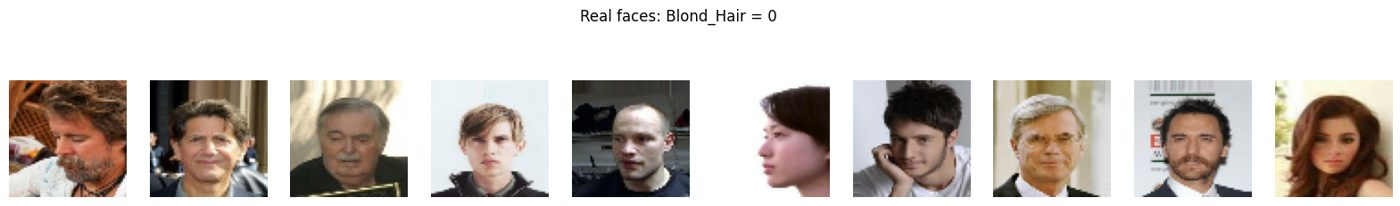

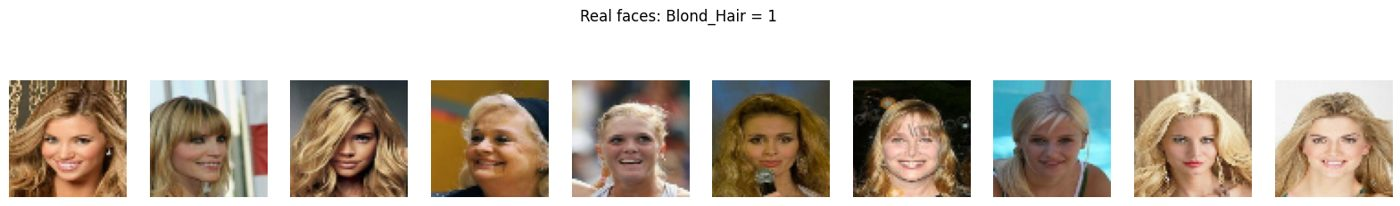

In [7]:
real_imgs, real_labels = next(iter(train))
blond_idx = np.where(real_labels.numpy()[:, 1] == 1)[0][:10]
other_idx = np.where(real_labels.numpy()[:, 1] == 0)[0][:10]
if len(other_idx): display(real_imgs.numpy()[other_idx], cmap=None, title="Real faces: Blond_Hair = 0")
if len(blond_idx): display(real_imgs.numpy()[blond_idx], cmap=None, title="Real faces: Blond_Hair = 1")

## 2. Build the GAN

In [8]:
# Critic: image (64x64x3) + label map (64x64x2)  ->  score
critic_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
critic_label_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CLASSES))
x = layers.Concatenate(axis=-1)([critic_input, critic_label_input])
x = layers.Conv2D(64, kernel_size=4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Dropout(0.3)(x)
x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Dropout(0.3)(x)
x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Dropout(0.3)(x)
x = layers.Conv2D(1, kernel_size=4, strides=1, padding="valid")(x)
critic_output = layers.Flatten()(x)
critic = models.Model([critic_input, critic_label_input], critic_output, name="critic")
critic.summary()

Model: "critic"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 64, 64, 2) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64, 5) │          0 │ input_layer[0][0… │
│ (Concatenate)       │                   │            │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │      5,184 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 32, 32,    │          0 │ conv2d[0][0]      │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16,    │    131,200 │ leaky_re_lu[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 16, 16,    │          0 │ conv2d_1[0][0]    │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 16, 16,    │          0 │ leaky_re_lu_1[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 8, 8, 128) │    262,272 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 8, 8, 128) │          0 │ conv2d_2[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 8, 8, 128) │          0 │ leaky_re_lu_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 4, 4, 128) │    262,272 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 4, 4, 128) │          0 │ conv2d_3[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 4, 4, 128) │          0 │ leaky_re_lu_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 1, 1, 1)   │      2,049 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 1)         │          0 │ conv2d_4[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 662,977 (2.53 MB)

 Trainable params: 662,977 (2.53 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Generator: noise z (32) + one-hot label (2)  ->  64x64x3 image
generator_input = layers.Input(shape=(Z_DIM,))
generator_label_input = layers.Input(shape=(CLASSES,))
x = layers.Concatenate(axis=-1)([generator_input, generator_label_input])
x = layers.Reshape((1, 1, Z_DIM + CLASSES))(x)
x = layers.Conv2DTranspose(128, kernel_size=4, strides=1, padding="valid", use_bias=False)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2DTranspose(128, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2DTranspose(128, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2DTranspose(64, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
generator_output = layers.Conv2DTranspose(CHANNELS, kernel_size=4, strides=2, padding="same", activation="tanh")(x)
generator = models.Model([generator_input, generator_label_input], generator_output, name="generator")
generator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 32)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 34)        │          0 │ input_layer_2[0]… │
│ (Concatenate)       │                   │            │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 34)  │          0 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 4, 4, 128) │     69,632 │ reshape[0][0]     │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 4, 4, 128) │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_4       │ (None, 4, 4, 128) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 8, 8, 128) │    262,144 │ leaky_re_lu_4[0]… │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 128) │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_5       │ (None, 8, 8, 128) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 16, 16,    │    262,144 │ leaky_re_lu_5[0]… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_6       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_3  │ (None, 32, 32,    │    131,072 │ leaky_re_lu_6[0]… │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_7       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_4  │ (None, 64, 64, 3) │      3,075 │ leaky_re_lu_7[0]… │
│ (Conv2DTranspose)   │                   │            │                 

 Total params: 729,859 (2.78 MB)

 Trainable params: 728,963 (2.78 MB)

 Non-trainable params: 896 (3.50 KB)

In [10]:
class ConditionalWGAN(models.Model):
    def __init__(self, critic, generator, latent_dim, critic_steps, gp_weight):
        super().__init__()
        self.critic = critic
        self.generator = generator
        self.latent_dim = latent_dim
        self.critic_steps = critic_steps
        self.gp_weight = gp_weight

    def compile(self, c_optimizer, g_optimizer):
        super().compile()
        self.c_optimizer = c_optimizer
        self.g_optimizer = g_optimizer
        self.c_wass_loss_metric = metrics.Mean(name="c_wass_loss")
        self.c_gp_metric = metrics.Mean(name="c_gp")
        self.c_loss_metric = metrics.Mean(name="c_loss")
        self.g_loss_metric = metrics.Mean(name="g_loss")

    @property
    def metrics(self):
        return [self.c_loss_metric, self.c_wass_loss_metric, self.c_gp_metric, self.g_loss_metric]

    # ---- label formatting (CHANGED) -------------------------------------------------
    def generator_labels(self, one_hot_labels):
        """Generator expects a flat one-hot vector: (batch, CLASSES)."""
        return tf.cast(one_hot_labels, tf.float32)

    def critic_labels(self, one_hot_labels):
        """Critic expects a label 'image': (batch, IMAGE_SIZE, IMAGE_SIZE, CLASSES),
        i.e. the one-hot vector copied to every pixel so it can be concatenated with the RGB channels."""
        labels = tf.cast(one_hot_labels, tf.float32)[:, None, None, :]           # (B, 1, 1, C)
        return tf.tile(labels, [1, IMAGE_SIZE, IMAGE_SIZE, 1])                   # (B, 64, 64, C)
    # ---------------------------------------------------------------------------------

    def gradient_penalty(self, batch_size, real_images, fake_images, critic_label_maps):
        # interpolate between real and fake images (alpha ~ U[0, 1], as in WGAN-GP)
        alpha = tf.random.uniform([batch_size, 1, 1, 1], 0.0, 1.0)
        interpolated = real_images + alpha * (fake_images - real_images)
        with tf.GradientTape() as gp_tape:
            gp_tape.watch(interpolated)
            pred = self.critic([interpolated, critic_label_maps], training=True)
        grads = gp_tape.gradient(pred, [interpolated])[0]
        norm = tf.sqrt(tf.reduce_sum(tf.square(grads), axis=[1, 2, 3]) + 1e-12)
        return tf.reduce_mean((norm - 1.0) ** 2)

    def train_step(self, data):
        real_images, one_hot_labels = data
        real_images = tf.cast(real_images, tf.float32)

        # CHANGED: build each network's label input in the format its Input layer expects
        g_labels = self.generator_labels(one_hot_labels)      # (B, 2)        -> generator
        c_labels = self.critic_labels(one_hot_labels)         # (B, 64, 64, 2) -> critic

        batch_size = tf.shape(real_images)[0]

        # ---- train the critic several times per generator step ----
        for _ in range(self.critic_steps):
            z = tf.random.normal(shape=(batch_size, self.latent_dim))
            with tf.GradientTape() as tape:
                fake_images = self.generator([z, g_labels], training=True)
                fake_pred = self.critic([fake_images, c_labels], training=True)
                real_pred = self.critic([real_images, c_labels], training=True)
                c_wass_loss = tf.reduce_mean(fake_pred) - tf.reduce_mean(real_pred)
                c_gp = self.gradient_penalty(batch_size, real_images, fake_images, c_labels)
                c_loss = c_wass_loss + c_gp * self.gp_weight
            c_grad = tape.gradient(c_loss, self.critic.trainable_variables)
            self.c_optimizer.apply_gradients(zip(c_grad, self.critic.trainable_variables))

        # ---- train the generator ----
        z = tf.random.normal(shape=(batch_size, self.latent_dim))
        with tf.GradientTape() as tape:
            fake_images = self.generator([z, g_labels], training=True)
            fake_pred = self.critic([fake_images, c_labels], training=True)
            g_loss = -tf.reduce_mean(fake_pred)
        g_grad = tape.gradient(g_loss, self.generator.trainable_variables)
        self.g_optimizer.apply_gradients(zip(g_grad, self.generator.trainable_variables))

        self.c_loss_metric.update_state(c_loss)
        self.c_wass_loss_metric.update_state(c_wass_loss)
        self.c_gp_metric.update_state(c_gp)
        self.g_loss_metric.update_state(g_loss)
        return {m.name: m.result() for m in self.metrics}

In [11]:
cgan = ConditionalWGAN(critic=critic, generator=generator, latent_dim=Z_DIM,
                       critic_steps=CRITIC_STEPS, gp_weight=GP_WEIGHT)

## 3. Train the GAN

Epoch 1/2000
Saved to ./output/generated_img_0001_label_0.png


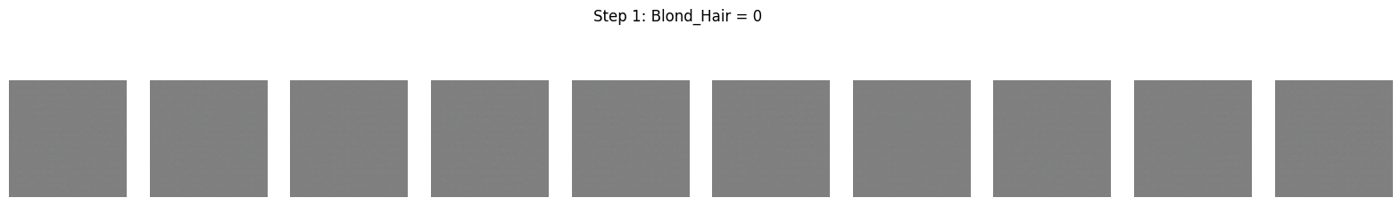

Saved to ./output/generated_img_0001_label_1.png


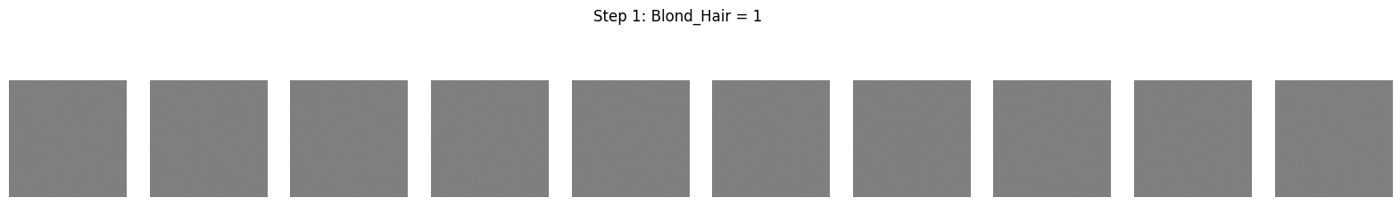

1/1 - 53s - 53s/step - c_gp: 0.7356 - c_loss: 7.2622 - c_wass_loss: -9.3795e-02 - g_loss: -2.2377e-02
Epoch 2/2000
1/1 - 0s - 267ms/step - c_gp: 0.7245 - c_loss: 7.0705 - c_wass_loss: -1.7454e-01 - g_loss: -4.8616e-02
Epoch 3/2000
1/1 - 0s - 267ms/step - c_gp: 0.7133 - c_loss: 6.8244 - c_wass_loss: -3.0841e-01 - g_loss: -6.8075e-02
Epoch 4/2000
1/1 - 0s - 267ms/step - c_gp: 0.6925 - c_loss: 6.4920 - c_wass_loss: -4.3335e-01 - g_loss: -8.7898e-02
Epoch 5/2000
1/1 - 0s - 269ms/step - c_gp: 0.6633 - c_loss: 5.9242 - c_wass_loss: -7.0847e-01 - g_loss: -8.8018e-02
Epoch 6/2000
1/1 - 0s - 272ms/step - c_gp: 0.6354 - c_loss: 5.2386 - c_wass_loss: -1.1153e+00 - g_loss: -5.9883e-02
Epoch 7/2000
1/1 - 0s - 269ms/step - c_gp: 0.6095 - c_loss: 4.6286 - c_wass_loss: -1.4669e+00 - g_loss: -7.9772e-02
Epoch 8/2000
1/1 - 0s - 273ms/step - c_gp: 0.5644 - c_loss: 3.4411 - c_wass_loss: -2.2029e+00 - g_loss: 0.0497
Epoch 9/2000
1/1 - 0s - 271ms/step - c_gp: 0.5177 - c_loss: 1.9329 - c_wass_loss: -3.2438e+

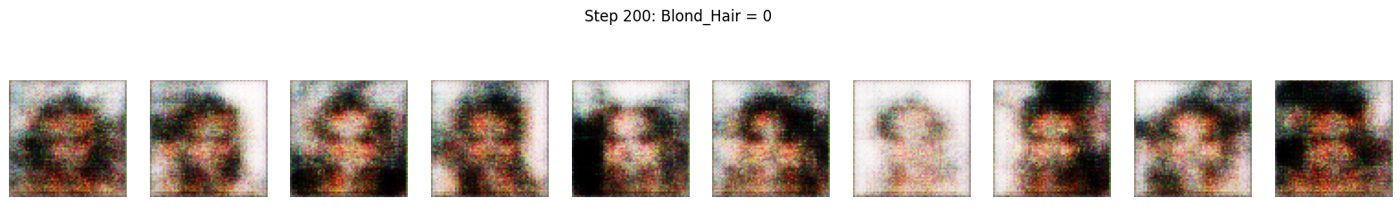

Saved to ./output/generated_img_0200_label_1.png


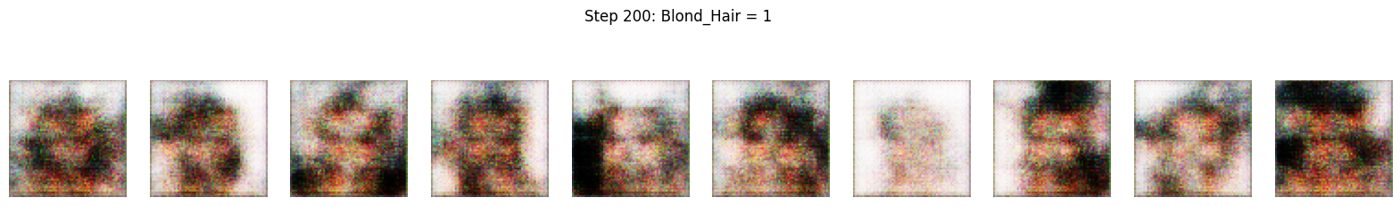

1/1 - 2s - 2s/step - c_gp: 0.1853 - c_loss: -9.0439e+00 - c_wass_loss: -1.0897e+01 - g_loss: 116.2559
Epoch 201/2000
1/1 - 0s - 308ms/step - c_gp: 0.1695 - c_loss: -1.0280e+01 - c_wass_loss: -1.1975e+01 - g_loss: 119.6645
Epoch 202/2000
1/1 - 0s - 310ms/step - c_gp: 0.2094 - c_loss: -1.4626e+01 - c_wass_loss: -1.6720e+01 - g_loss: 128.7104
Epoch 203/2000
1/1 - 0s - 314ms/step - c_gp: 0.2007 - c_loss: -1.1399e+01 - c_wass_loss: -1.3406e+01 - g_loss: 125.2612
Epoch 204/2000
1/1 - 0s - 341ms/step - c_gp: 0.1891 - c_loss: -9.7208e+00 - c_wass_loss: -1.1611e+01 - g_loss: 115.5915
Epoch 205/2000
1/1 - 1s - 562ms/step - c_gp: 0.1726 - c_loss: -8.4044e+00 - c_wass_loss: -1.0130e+01 - g_loss: 111.2049
Epoch 206/2000
1/1 - 1s - 558ms/step - c_gp: 0.1833 - c_loss: -9.9823e+00 - c_wass_loss: -1.1815e+01 - g_loss: 104.3972
Epoch 207/2000
1/1 - 1s - 563ms/step - c_gp: 0.1972 - c_loss: -9.3589e+00 - c_wass_loss: -1.1331e+01 - g_loss: 103.0816
Epoch 208/2000
1/1 - 1s - 539ms/step - c_gp: 0.2076 - c_lo

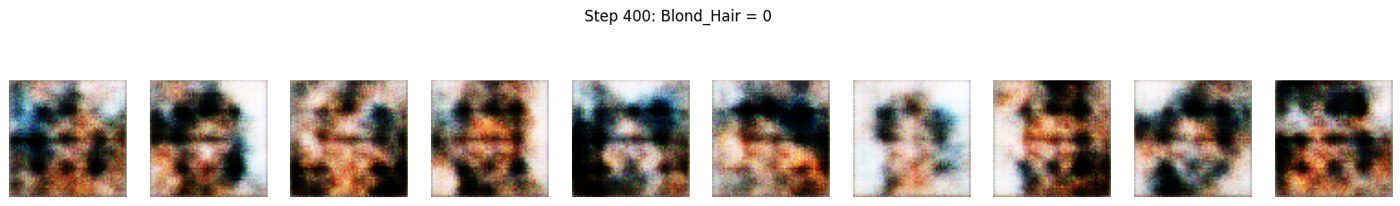

Saved to ./output/generated_img_0400_label_1.png


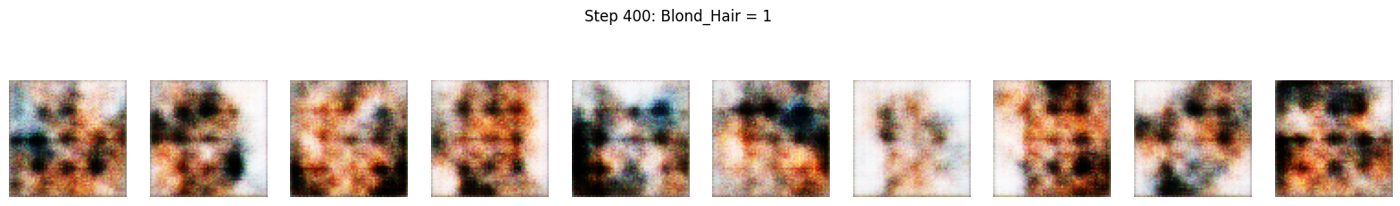

1/1 - 2s - 2s/step - c_gp: 0.1005 - c_loss: -8.3179e+00 - c_wass_loss: -9.3232e+00 - g_loss: 79.1560
Epoch 401/2000
1/1 - 0s - 303ms/step - c_gp: 0.1021 - c_loss: -3.1446e+00 - c_wass_loss: -4.1654e+00 - g_loss: 76.0722
Epoch 402/2000
1/1 - 0s - 300ms/step - c_gp: 0.1047 - c_loss: -3.8892e+00 - c_wass_loss: -4.9365e+00 - g_loss: 70.0354
Epoch 403/2000
1/1 - 0s - 306ms/step - c_gp: 0.0960 - c_loss: 0.1978 - c_wass_loss: -7.6236e-01 - g_loss: 71.3667
Epoch 404/2000
1/1 - 0s - 336ms/step - c_gp: 0.0754 - c_loss: -2.4707e+00 - c_wass_loss: -3.2249e+00 - g_loss: 71.5937
Epoch 405/2000
1/1 - 1s - 565ms/step - c_gp: 0.0684 - c_loss: -5.5600e+00 - c_wass_loss: -6.2437e+00 - g_loss: 74.8345
Epoch 406/2000
1/1 - 1s - 552ms/step - c_gp: 0.0650 - c_loss: -4.3947e+00 - c_wass_loss: -5.0447e+00 - g_loss: 73.2476
Epoch 407/2000
1/1 - 1s - 581ms/step - c_gp: 0.0589 - c_loss: -3.8166e+00 - c_wass_loss: -4.4055e+00 - g_loss: 70.4006
Epoch 408/2000
1/1 - 1s - 582ms/step - c_gp: 0.0678 - c_loss: -4.3087e+

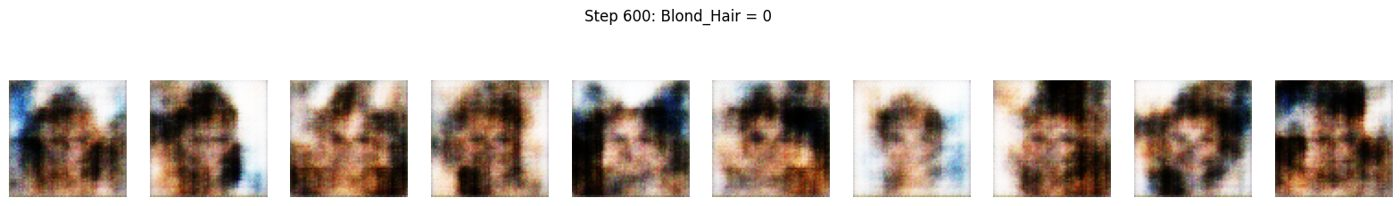

Saved to ./output/generated_img_0600_label_1.png


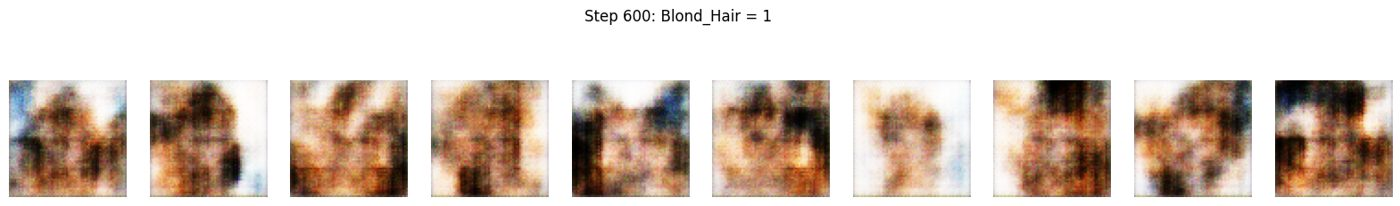

1/1 - 2s - 2s/step - c_gp: 0.0631 - c_loss: -5.8843e+00 - c_wass_loss: -6.5154e+00 - g_loss: 17.7145
Epoch 601/2000
1/1 - 0s - 307ms/step - c_gp: 0.0690 - c_loss: -8.8090e+00 - c_wass_loss: -9.4994e+00 - g_loss: 20.1024
Epoch 602/2000
1/1 - 0s - 303ms/step - c_gp: 0.0728 - c_loss: -8.5474e+00 - c_wass_loss: -9.2751e+00 - g_loss: 30.8493
Epoch 603/2000
1/1 - 0s - 303ms/step - c_gp: 0.0741 - c_loss: -2.0740e+00 - c_wass_loss: -2.8149e+00 - g_loss: 24.7691
Epoch 604/2000
1/1 - 0s - 301ms/step - c_gp: 0.0709 - c_loss: -6.4287e+00 - c_wass_loss: -7.1378e+00 - g_loss: 20.3469
Epoch 605/2000
1/1 - 1s - 548ms/step - c_gp: 0.0674 - c_loss: -5.2042e+00 - c_wass_loss: -5.8787e+00 - g_loss: 23.0386
Epoch 606/2000
1/1 - 1s - 622ms/step - c_gp: 0.0627 - c_loss: -1.0874e+01 - c_wass_loss: -1.1501e+01 - g_loss: 34.1995
Epoch 607/2000
1/1 - 1s - 612ms/step - c_gp: 0.0829 - c_loss: -6.5367e+00 - c_wass_loss: -7.3657e+00 - g_loss: 45.7719
Epoch 608/2000
1/1 - 1s - 619ms/step - c_gp: 0.1014 - c_loss: -3.8

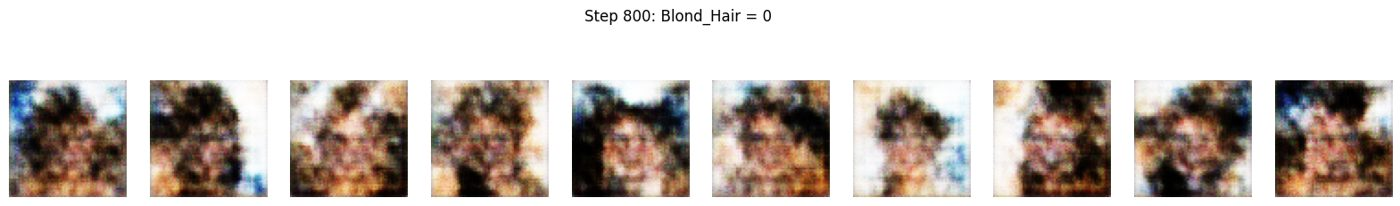

Saved to ./output/generated_img_0800_label_1.png


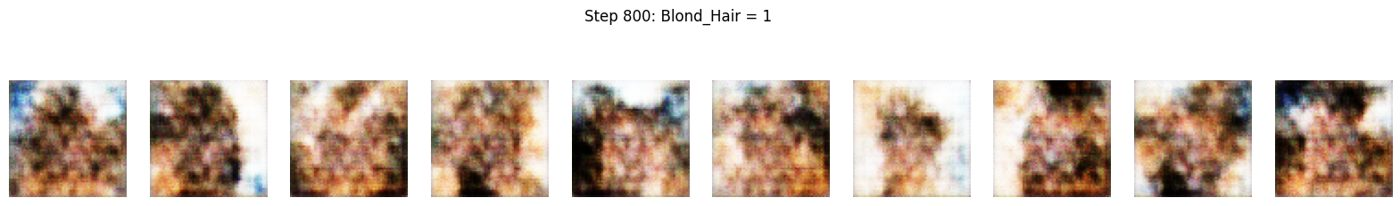

1/1 - 2s - 2s/step - c_gp: 0.0763 - c_loss: -4.8229e+00 - c_wass_loss: -5.5864e+00 - g_loss: -2.7604e+01
Epoch 801/2000
1/1 - 0s - 295ms/step - c_gp: 0.0587 - c_loss: -4.5896e+00 - c_wass_loss: -5.1769e+00 - g_loss: -1.9863e+01
Epoch 802/2000
1/1 - 0s - 301ms/step - c_gp: 0.0683 - c_loss: -8.6264e+00 - c_wass_loss: -9.3093e+00 - g_loss: -1.8713e+01
Epoch 803/2000
1/1 - 0s - 303ms/step - c_gp: 0.0725 - c_loss: -5.0472e+00 - c_wass_loss: -5.7718e+00 - g_loss: -1.9542e+01
Epoch 804/2000
1/1 - 0s - 314ms/step - c_gp: 0.0717 - c_loss: -8.0239e+00 - c_wass_loss: -8.7405e+00 - g_loss: -1.7499e+01
Epoch 805/2000
1/1 - 1s - 586ms/step - c_gp: 0.0766 - c_loss: -7.9629e+00 - c_wass_loss: -8.7291e+00 - g_loss: -1.4050e+01
Epoch 806/2000
1/1 - 1s - 570ms/step - c_gp: 0.0768 - c_loss: -6.4321e+00 - c_wass_loss: -7.2002e+00 - g_loss: -2.1481e+01
Epoch 807/2000
1/1 - 1s - 690ms/step - c_gp: 0.0848 - c_loss: -6.4341e+00 - c_wass_loss: -7.2826e+00 - g_loss: -2.6204e+01
Epoch 808/2000
1/1 - 1s - 692ms/st

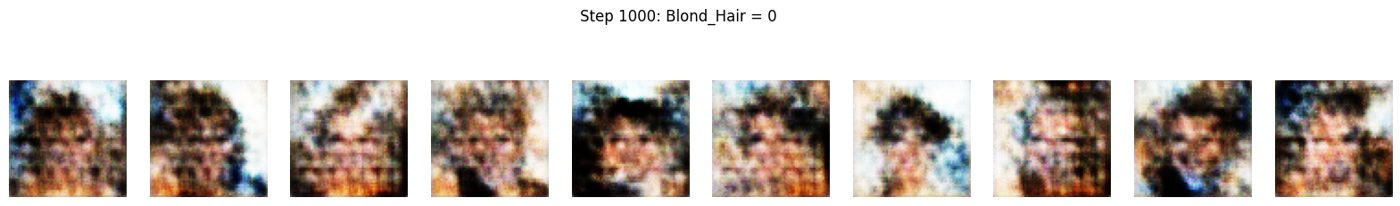

Saved to ./output/generated_img_1000_label_1.png


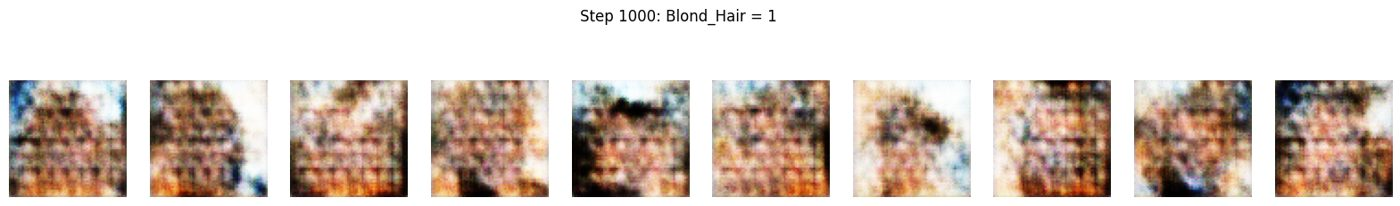

1/1 - 2s - 2s/step - c_gp: 0.0885 - c_loss: -5.3859e+00 - c_wass_loss: -6.2711e+00 - g_loss: -1.1096e+01
Epoch 1001/2000
1/1 - 0s - 304ms/step - c_gp: 0.0843 - c_loss: -9.8144e+00 - c_wass_loss: -1.0658e+01 - g_loss: -1.3158e+01
Epoch 1002/2000
1/1 - 0s - 302ms/step - c_gp: 0.0819 - c_loss: -8.2970e+00 - c_wass_loss: -9.1162e+00 - g_loss: -2.2300e+01
Epoch 1003/2000
1/1 - 0s - 344ms/step - c_gp: 0.0918 - c_loss: -1.0141e+01 - c_wass_loss: -1.1059e+01 - g_loss: -1.6053e+01
Epoch 1004/2000
1/1 - 1s - 673ms/step - c_gp: 0.0949 - c_loss: -7.4195e+00 - c_wass_loss: -8.3688e+00 - g_loss: -6.9131e+00
Epoch 1005/2000
1/1 - 1s - 698ms/step - c_gp: 0.0895 - c_loss: -5.3646e+00 - c_wass_loss: -6.2594e+00 - g_loss: -8.2256e+00
Epoch 1006/2000
1/1 - 1s - 692ms/step - c_gp: 0.0854 - c_loss: -5.9635e+00 - c_wass_loss: -6.8177e+00 - g_loss: -6.8446e+00
Epoch 1007/2000
1/1 - 1s - 682ms/step - c_gp: 0.0684 - c_loss: -1.3431e+01 - c_wass_loss: -1.4114e+01 - g_loss: -6.5433e+00
Epoch 1008/2000
1/1 - 1s - 

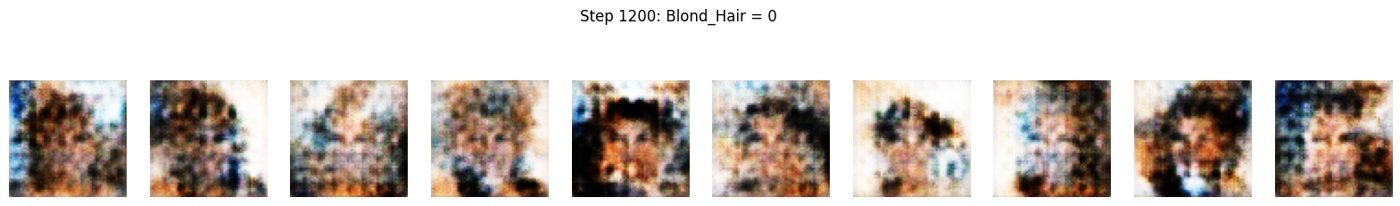

Saved to ./output/generated_img_1200_label_1.png


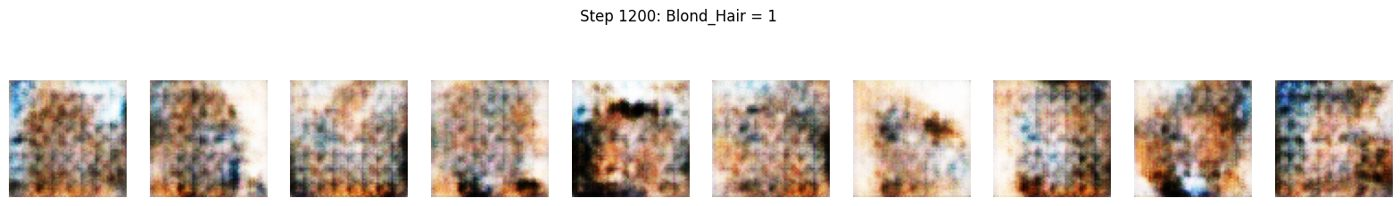

1/1 - 2s - 2s/step - c_gp: 0.0445 - c_loss: -7.1995e+00 - c_wass_loss: -7.6445e+00 - g_loss: -3.8859e+01
Epoch 1201/2000
1/1 - 0s - 303ms/step - c_gp: 0.0409 - c_loss: -6.0654e+00 - c_wass_loss: -6.4742e+00 - g_loss: -3.7013e+01
Epoch 1202/2000
1/1 - 0s - 300ms/step - c_gp: 0.0495 - c_loss: -4.7292e+00 - c_wass_loss: -5.2239e+00 - g_loss: -3.0462e+01
Epoch 1203/2000
1/1 - 0s - 300ms/step - c_gp: 0.0606 - c_loss: -4.2965e+00 - c_wass_loss: -4.9023e+00 - g_loss: -3.1792e+01
Epoch 1204/2000
1/1 - 0s - 381ms/step - c_gp: 0.0726 - c_loss: -8.6750e+00 - c_wass_loss: -9.4007e+00 - g_loss: -3.9212e+01
Epoch 1205/2000
1/1 - 1s - 661ms/step - c_gp: 0.0723 - c_loss: -5.5174e+00 - c_wass_loss: -6.2404e+00 - g_loss: -5.5007e+01
Epoch 1206/2000
1/1 - 1s - 681ms/step - c_gp: 0.0635 - c_loss: -7.2176e+00 - c_wass_loss: -7.8522e+00 - g_loss: -5.4079e+01
Epoch 1207/2000
1/1 - 1s - 686ms/step - c_gp: 0.0726 - c_loss: -4.9705e+00 - c_wass_loss: -5.6966e+00 - g_loss: -5.5300e+01
Epoch 1208/2000
1/1 - 1s - 

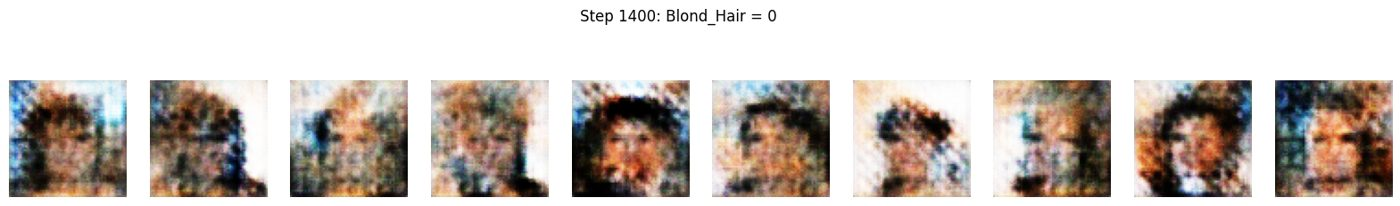

Saved to ./output/generated_img_1400_label_1.png


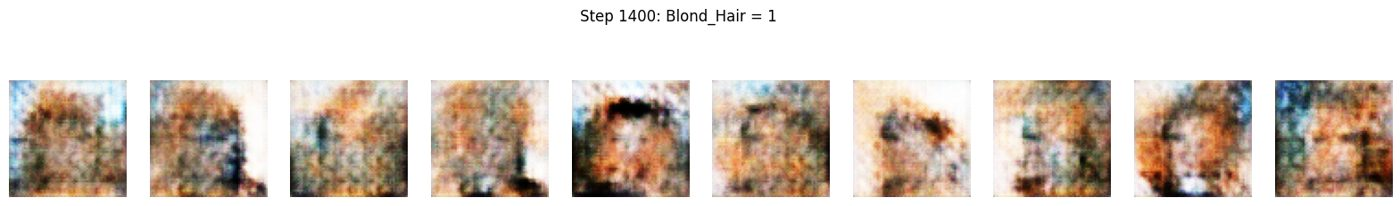

1/1 - 2s - 2s/step - c_gp: 0.0558 - c_loss: -4.2003e+00 - c_wass_loss: -4.7580e+00 - g_loss: -7.1951e+01
Epoch 1401/2000
1/1 - 0s - 308ms/step - c_gp: 0.0474 - c_loss: -7.0861e+00 - c_wass_loss: -7.5601e+00 - g_loss: -6.8456e+01
Epoch 1402/2000
1/1 - 0s - 302ms/step - c_gp: 0.0504 - c_loss: -2.6723e+00 - c_wass_loss: -3.1759e+00 - g_loss: -5.4418e+01
Epoch 1403/2000
1/1 - 0s - 357ms/step - c_gp: 0.0401 - c_loss: -9.5660e+00 - c_wass_loss: -9.9673e+00 - g_loss: -5.8376e+01
Epoch 1404/2000
1/1 - 1s - 706ms/step - c_gp: 0.0482 - c_loss: -5.8158e+00 - c_wass_loss: -6.2980e+00 - g_loss: -5.5394e+01
Epoch 1405/2000
1/1 - 1s - 711ms/step - c_gp: 0.0546 - c_loss: -5.7663e+00 - c_wass_loss: -6.3123e+00 - g_loss: -5.8092e+01
Epoch 1406/2000
1/1 - 1s - 734ms/step - c_gp: 0.0647 - c_loss: -6.2291e+00 - c_wass_loss: -6.8757e+00 - g_loss: -5.0347e+01
Epoch 1407/2000
1/1 - 1s - 761ms/step - c_gp: 0.0545 - c_loss: -5.7299e+00 - c_wass_loss: -6.2752e+00 - g_loss: -4.3604e+01
Epoch 1408/2000
1/1 - 1s - 

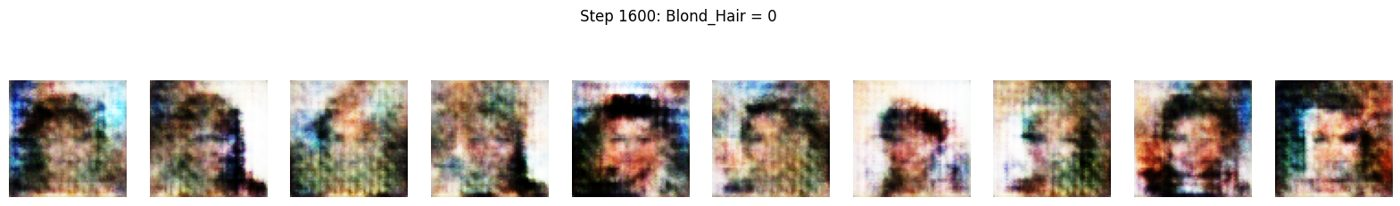

Saved to ./output/generated_img_1600_label_1.png


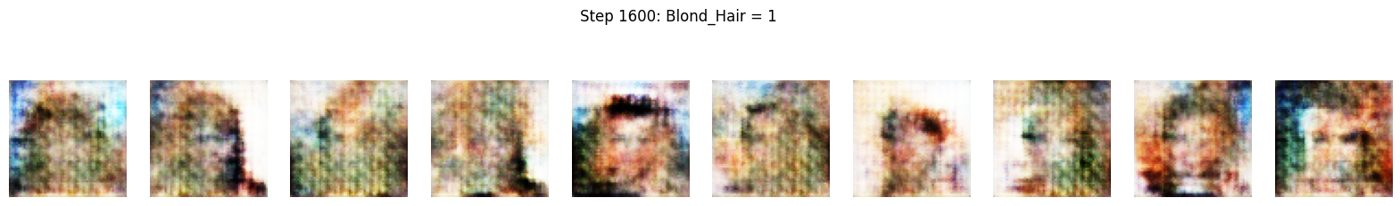

1/1 - 2s - 2s/step - c_gp: 0.0430 - c_loss: -4.3375e+00 - c_wass_loss: -4.7676e+00 - g_loss: -3.1371e+01
Epoch 1601/2000
1/1 - 0s - 375ms/step - c_gp: 0.0401 - c_loss: 0.1403 - c_wass_loss: -2.6072e-01 - g_loss: -3.4250e+01
Epoch 1602/2000
1/1 - 0s - 303ms/step - c_gp: 0.0443 - c_loss: -2.2250e+00 - c_wass_loss: -2.6680e+00 - g_loss: -3.3495e+01
Epoch 1603/2000
1/1 - 0s - 304ms/step - c_gp: 0.0579 - c_loss: -8.2000e+00 - c_wass_loss: -8.7785e+00 - g_loss: -2.8692e+01
Epoch 1604/2000
1/1 - 0s - 308ms/step - c_gp: 0.0403 - c_loss: -6.5656e-01 - c_wass_loss: -1.0598e+00 - g_loss: -3.5809e+01
Epoch 1605/2000
1/1 - 0s - 306ms/step - c_gp: 0.0399 - c_loss: -8.0317e+00 - c_wass_loss: -8.4311e+00 - g_loss: -4.0193e+01
Epoch 1606/2000
1/1 - 0s - 309ms/step - c_gp: 0.0447 - c_loss: -4.5470e+00 - c_wass_loss: -4.9935e+00 - g_loss: -3.1072e+01
Epoch 1607/2000
1/1 - 0s - 308ms/step - c_gp: 0.0607 - c_loss: -9.7855e+00 - c_wass_loss: -1.0392e+01 - g_loss: -2.8753e+01
Epoch 1608/2000
1/1 - 0s - 309ms

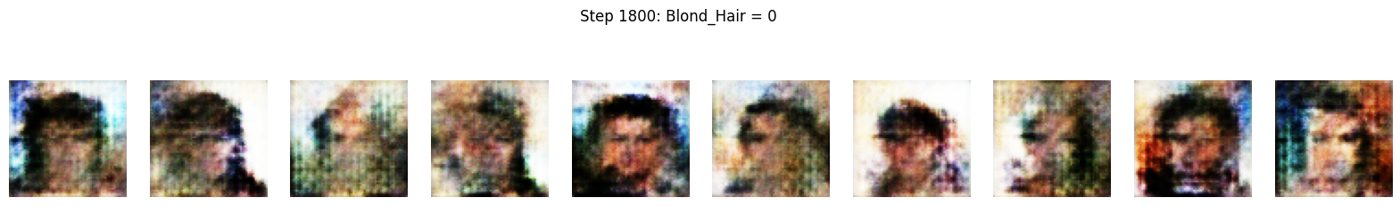

Saved to ./output/generated_img_1800_label_1.png


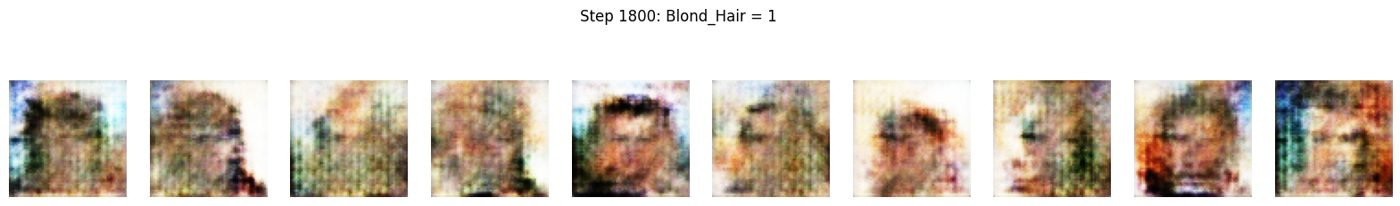

1/1 - 1s - 1s/step - c_gp: 0.0319 - c_loss: -3.4470e+00 - c_wass_loss: -3.7661e+00 - g_loss: -3.8876e+01
Epoch 1801/2000
1/1 - 0s - 299ms/step - c_gp: 0.0377 - c_loss: -9.7963e-01 - c_wass_loss: -1.3567e+00 - g_loss: -3.4463e+01
Epoch 1802/2000
1/1 - 0s - 299ms/step - c_gp: 0.0311 - c_loss: -7.1760e+00 - c_wass_loss: -7.4867e+00 - g_loss: -3.9561e+01
Epoch 1803/2000
1/1 - 0s - 301ms/step - c_gp: 0.0407 - c_loss: -3.5783e+00 - c_wass_loss: -3.9852e+00 - g_loss: -4.8891e+01
Epoch 1804/2000
1/1 - 0s - 296ms/step - c_gp: 0.0427 - c_loss: -6.9741e+00 - c_wass_loss: -7.4008e+00 - g_loss: -5.1187e+01
Epoch 1805/2000
1/1 - 0s - 297ms/step - c_gp: 0.0403 - c_loss: -1.0311e+01 - c_wass_loss: -1.0714e+01 - g_loss: -4.8093e+01
Epoch 1806/2000
1/1 - 0s - 298ms/step - c_gp: 0.0373 - c_loss: -2.7685e+00 - c_wass_loss: -3.1419e+00 - g_loss: -4.4606e+01
Epoch 1807/2000
1/1 - 0s - 298ms/step - c_gp: 0.0387 - c_loss: -5.5335e+00 - c_wass_loss: -5.9206e+00 - g_loss: -5.0293e+01
Epoch 1808/2000
1/1 - 0s - 

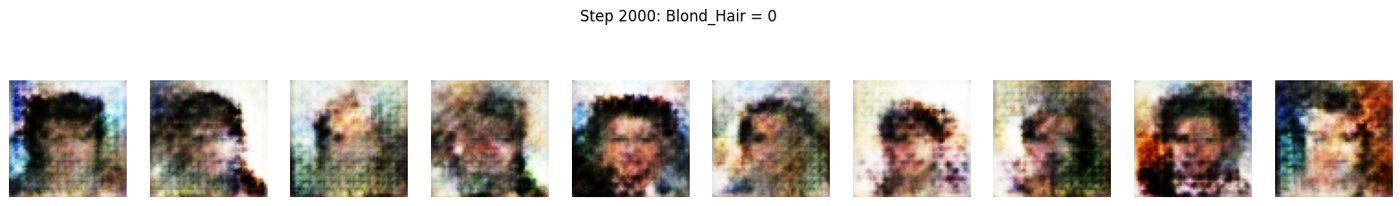

Saved to ./output/generated_img_2000_label_1.png


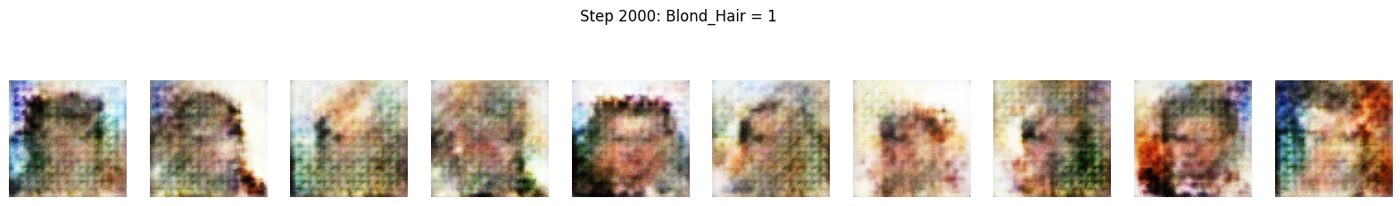

1/1 - 2s - 2s/step - c_gp: 0.0476 - c_loss: 3.3033 - c_wass_loss: 2.8269 - g_loss: 5.0786


In [12]:
cgan.compile(
    c_optimizer=optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=ADAM_BETA_1, beta_2=ADAM_BETA_2),
    g_optimizer=optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=ADAM_BETA_1, beta_2=ADAM_BETA_2),
)

FIXED_Z = tf.random.normal(shape=(10, Z_DIM), seed=1)


class ImageGenerator(callbacks.Callback):
    """Every `every` epochs, generate the SAME 10 noise vectors with label 0 and label 1."""
    def __init__(self, every=200):
        super().__init__()
        self.every = every

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every and epoch != 0:
            return
        for lab, onehot in [(0, [1, 0]), (1, [0, 1])]:
            y = tf.constant(np.repeat([onehot], 10, axis=0), dtype=tf.float32)
            imgs = self.model.generator([FIXED_Z, y], training=False).numpy()
            display(imgs, cmap=None, save_to=f"./output/generated_img_{epoch + 1:04d}_label_{lab}.png",
                    title=f"Step {epoch + 1}: Blond_Hair = {lab}")


history = cgan.fit(
    train.repeat(),
    epochs=EPOCHS * 100,
    steps_per_epoch=STEPS_PER_EPOCH,
    callbacks=[ImageGenerator(every=200 if not SMOKE_TEST else 50)],
    verbose=2,
)

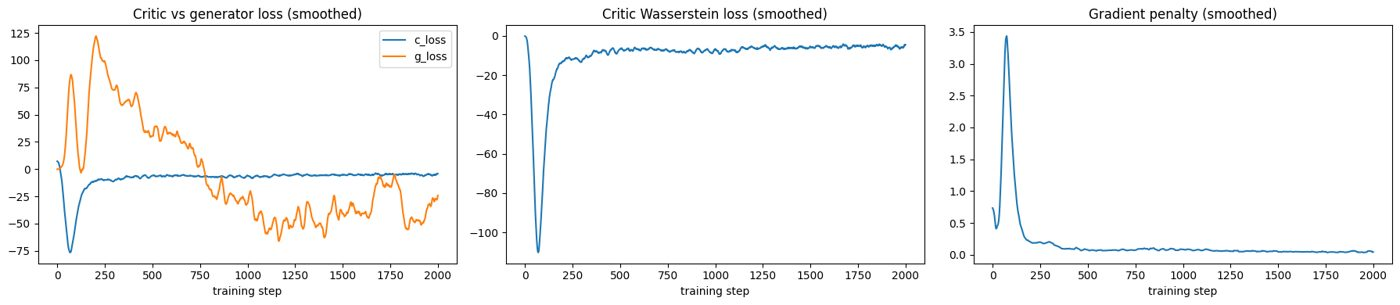

                 1999
c_gp         0.047641
c_loss       3.303329
c_wass_loss  2.826918
g_loss       5.078567


In [13]:
generator.save("./models/generator.keras")
critic.save("./models/critic.keras")

h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
h[["c_loss", "g_loss"]].rolling(25, min_periods=1).mean().plot(ax=ax[0], title="Critic vs generator loss (smoothed)")
h["c_wass_loss"].rolling(25, min_periods=1).mean().plot(ax=ax[1], title="Critic Wasserstein loss (smoothed)")
h["c_gp"].rolling(25, min_periods=1).mean().plot(ax=ax[2], title="Gradient penalty (smoothed)")
for a in ax: a.set_xlabel("training step")
plt.tight_layout(); plt.savefig("./output/loss_curves.png"); plt.show()
print(h.tail(1).T)

## 4. Generate images

Saved to ./output/final_label_0.png


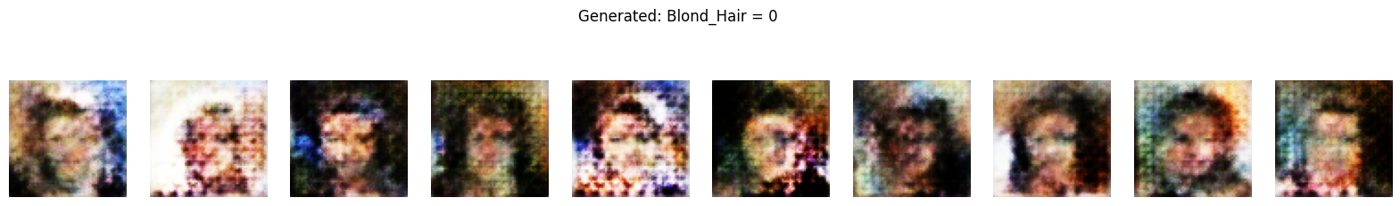

Saved to ./output/final_label_1.png


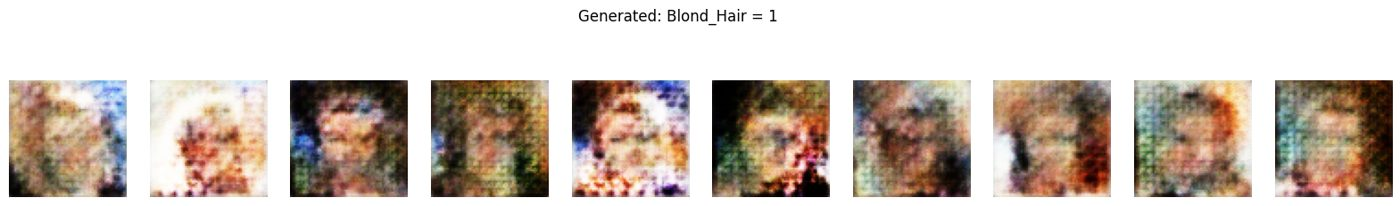

In [14]:
# Same noise vector, different label: only the conditioning input changes
z_sample = np.random.normal(size=(10, Z_DIM)).astype("float32")
imgs_0 = cgan.generator.predict([z_sample, np.repeat([[1, 0]], 10, axis=0).astype("float32")], verbose=0)
imgs_1 = cgan.generator.predict([z_sample, np.repeat([[0, 1]], 10, axis=0).astype("float32")], verbose=0)
display(imgs_0, cmap=None, title="Generated: Blond_Hair = 0", save_to="./output/final_label_0.png")
display(imgs_1, cmap=None, title="Generated: Blond_Hair = 1", save_to="./output/final_label_1.png")

## 5. How accurate is the conditioning?

A GAN has no built-in "accuracy", so we measure how often generated images actually show the requested attribute.
We train a small, separate CNN classifier to predict `Blond_Hair` on **real** CelebA images, check its accuracy on
held-out real images, then use it to label 1,000 generated images per condition.

In [15]:
# Unshuffled copy of the data, so the classifier's train / held-out split does not overlap
clf_data = make_dataset(shuffle=False).map(lambda x, y: (preprocess(x), tf.cast(y, tf.float32)))
n_batches = int(clf_data.cardinality())
n_train = int(n_batches * 0.8)
clf_train = clf_data.take(n_train).shuffle(64).take(400 if not SMOKE_TEST else 4).prefetch(tf.data.AUTOTUNE)
clf_val = clf_data.skip(n_train).take(80 if not SMOKE_TEST else 2).cache()

classifier = models.Sequential([
    layers.Input((IMAGE_SIZE, IMAGE_SIZE, CHANNELS)),
    layers.Conv2D(32, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2D(64, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2D(128, 3, strides=2, padding="same", activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
], name="blond_classifier")
classifier.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
p = np.mean(int_labels)
classifier.fit(clf_train, epochs=3 if not SMOKE_TEST else 1,
               class_weight={0: 0.5 / (1 - p), 1: 0.5 / p}, verbose=2)

y_true, y_prob = [], []
for xb, yb in clf_val:
    y_true.append(yb.numpy()); y_prob.append(classifier.predict(xb, verbose=0).ravel())
y_true, y_pred = np.concatenate(y_true), (np.concatenate(y_prob) > 0.5).astype(int)
tpr = (y_pred[y_true == 1] == 1).mean() if (y_true == 1).any() else float("nan")
tnr = (y_pred[y_true == 0] == 0).mean()
print(f"Classifier on held-out REAL images:  accuracy={(y_pred == y_true).mean():.3f}  "
      f"blond recall={tpr:.3f}  non-blond recall={tnr:.3f}  balanced accuracy={(tpr + tnr) / 2:.3f}")

Found 202599 files belonging to 2 classes.
Epoch 1/3
400/400 - 66s - 165ms/step - accuracy: 0.3497 - loss: 0.6948
Epoch 2/3
400/400 - 62s - 154ms/step - accuracy: 0.3325 - loss: 0.6944
Epoch 3/3
400/400 - 62s - 155ms/step - accuracy: 0.3028 - loss: 0.6949
Classifier on held-out REAL images:  accuracy=0.146  blond recall=1.000  non-blond recall=0.000  balanced accuracy=0.500


In [16]:
N = 1000
z = np.random.normal(size=(N, Z_DIM)).astype("float32")
gen0 = cgan.generator.predict([z, np.repeat([[1, 0]], N, axis=0).astype("float32")], verbose=0)
gen1 = cgan.generator.predict([z, np.repeat([[0, 1]], N, axis=0).astype("float32")], verbose=0)
p0 = classifier.predict(gen0, verbose=0).ravel()
p1 = classifier.predict(gen1, verbose=0).ravel()

blond_rate_0 = (p0 > 0.5).mean()   # should be LOW
blond_rate_1 = (p1 > 0.5).mean()   # should be HIGH
cond_acc = ((1 - blond_rate_0) + blond_rate_1) / 2
results = pd.DataFrame({
    "requested label": ["Blond_Hair = 0", "Blond_Hair = 1"],
    "classified as blond": [f"{blond_rate_0:.1%}", f"{blond_rate_1:.1%}"],
    "mean P(blond)": [f"{p0.mean():.3f}", f"{p1.mean():.3f}"],
})
print(results.to_string(index=False))
print(f"\nConditional accuracy (generated image matches requested label): {cond_acc:.1%}")
print(f"Same z, label switched 0 -> 1: P(blond) increased for {(p1 > p0).mean():.1%} of samples")

requested label classified as blond mean P(blond)
 Blond_Hair = 0              100.0%         0.502
 Blond_Hair = 1              100.0%         0.502

Conditional accuracy (generated image matches requested label): 50.0%
Same z, label switched 0 -> 1: P(blond) increased for 0.0% of samples


In [22]:
# FINAL EVALUATION (replaces the evaluation in the two cells above, whose 50% result is NOT valid).
# Why: on the Colab dataset mount, data sets built a second time (the unshuffled `clf_data`, or reading files by name) did not pair
# images with the right labels, so those classifiers could only guess. The GAN's own training pipeline `train` IS correctly paired
# (see the real-face check in Section 1, where every Blond_Hair = 1 face is blond), so the evaluation classifier is trained on it.
hair = lambda g: ((np.asarray(g)[:, :16, 8:56, :] + 1) * 127.5).mean()   # mean brightness of the hair region (top quarter), 0-255
clf_src = train.map(lambda x, y: (x, y[:, 1]))
clf_tr = clf_src.take(400).prefetch(tf.data.AUTOTUNE); clf_va = clf_src.take(40).cache()
classifier = models.Sequential([
layers.Input((IMAGE_SIZE, IMAGE_SIZE, CHANNELS)),
layers.Conv2D(32, 3, padding="same", use_bias=False), layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling2D(),
layers.Conv2D(64, 3, padding="same", use_bias=False), layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling2D(),
layers.Conv2D(128, 3, padding="same", use_bias=False), layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling2D(),
layers.GlobalAveragePooling2D(),
layers.Dense(1, activation="sigmoid"),
], name="blond_classifier")
classifier.compile(optimizer=optimizers.Adam(3e-4), loss="binary_crossentropy", metrics=["accuracy"])
classifier.fit(clf_tr, epochs=2, class_weight={0: 0.5 / (1 - p), 1: 0.5 / p}, verbose=2)
val = [(yb.numpy(), classifier.predict(xb, verbose=0).ravel()) for xb, yb in clf_va]
y_true = np.concatenate([v[0] for v in val]); y_pred = (np.concatenate([v[1] for v in val]) > 0.5).astype(int)
tpr = (y_pred[y_true == 1] == 1).mean(); tnr = (y_pred[y_true == 0] == 0).mean()
print(f"Classifier on {len(y_true):,} real images: accuracy={(y_pred == y_true).mean():.3f}  blond recall={tpr:.3f}  non-blond recall={tnr:.3f}  balanced accuracy={(tpr + tnr) / 2:.3f}")
p0 = classifier.predict(gen0, verbose=0).ravel(); p1 = classifier.predict(gen1, verbose=0).ravel()
blond_rate_0 = (p0 > 0.5).mean(); blond_rate_1 = (p1 > 0.5).mean(); cond_acc = ((1 - blond_rate_0) + blond_rate_1) / 2
print(f"Mean hair-region brightness of generated faces (0-255): Blond_Hair=0 -> {hair(gen0):.1f}   Blond_Hair=1 -> {hair(gen1):.1f}")
print(f"Generated with Blond_Hair=0: classified blond {blond_rate_0:.1%}  (mean P(blond)={p0.mean():.3f})")
print(f"Generated with Blond_Hair=1: classified blond {blond_rate_1:.1%}  (mean P(blond)={p1.mean():.3f})")
print(f"Conditional accuracy (generated image matches requested label): {cond_acc:.1%}")
print(f"Same z, label switched 0 -> 1: P(blond) increased for {(p1 > p0).mean():.1%} of samples")

Epoch 1/2
400/400 - 174s - 434ms/step - accuracy: 0.8515 - loss: 0.3323
Epoch 2/2
400/400 - 56s - 139ms/step - accuracy: 0.8890 - loss: 0.2742
Classifier on 5,120 real images: accuracy=0.888  blond recall=0.896  non-blond recall=0.887  balanced accuracy=0.892
Mean hair-region brightness of generated faces (0-255): Blond_Hair=0 -> 102.5   Blond_Hair=1 -> 124.1
Generated with Blond_Hair=0: classified blond 15.2%  (mean P(blond)=0.227)
Generated with Blond_Hair=1: classified blond 87.0%  (mean P(blond)=0.788)
Conditional accuracy (generated image matches requested label): 85.9%
Same z, label switched 0 -> 1: P(blond) increased for 100.0% of samples


## 6. Observations about the output and its accuracy

**Training behaviour (loss curves).** The critic's Wasserstein loss dropped to about -110 in the first ~60 steps, while the gradient penalty spiked to about 3.4. Early on, the critic separates real faces from the generator's noise very easily. After roughly 300 steps the gradient penalty settled below 0.1, so the Lipschitz constraint was being satisfied. The Wasserstein loss rose steadily toward zero (about -5 by step 2,000), which means the critic's estimate of the distance between real and generated faces kept shrinking. The generator loss swings widely (+120 to -60). In a WGAN that is expected: the generator loss is only the critic's score, not a quality measure, so the critic loss and the images are the better guides.

**Image quality.** After 2,000 steps (about 256,000 images, roughly 1.3 passes over CelebA), the generator produces recognizable face layouts: an oval face, eye and mouth regions, hair framing the face, and a background. The images are still blurry and show a checkerboard texture, a known artifact of strided `Conv2DTranspose` layers. More training, upsampling + convolution instead of transposed convolution, and a higher resolution would be the next steps.

**Does the condition work?** Yes. With the same noise vector `z`, switching the label from 0 to 1 keeps the pose, face shape and background largely the same, but turns the hair lighter and yellower. So the network learned to treat `z` as "which face" and the label as "what hair colour". The effect is not perfectly confined to the hair: the label-1 images are also slightly lighter overall. The generator has partly learned "blond = brighter, warmer image", which is a correlation present in the training photos.

**Accuracy (measured with a separately trained blond-hair classifier):**

| Measurement | Result |
|---|---|
| Classifier on real CelebA faces (balanced accuracy) | 89.2% (blond recall 89.6%, non-blond recall 88.7%) |
| Generated with Blond_Hair = 1, classified blond | 87.0% (mean P(blond) = 0.79) |
| Generated with Blond_Hair = 0, classified blond | 15.2% (mean P(blond) = 0.23) |
| **Conditional accuracy** (image matches requested label) | **85.9%** |
| Same z, label 0 to 1: P(blond) increases | 100% of 1,000 samples |
| Mean hair-region brightness (0-255), label 0 vs label 1 | 102.5 vs 124.1 |

The generator obeys the requested label about 86% of the time. That is close to the ~89% ceiling set by the classifier itself, so part of the remaining error belongs to the classifier, not the GAN. The label has a consistent, one-directional effect: every single noise vector became more blond when the label was switched on.

**Caveats.** (1) Blond faces are only about 15% of CelebA, so the classifier used class weights and the results are reported per class. (2) The classifier was trained and checked on random batches of the training pipeline, so the real-image accuracy is approximate. (3) A first evaluation attempt reported 50%. Its data sets paired images with the wrong labels on the Colab dataset mount, so those classifiers could only guess. That result is invalid and was replaced by the cell above. (4) A classifier score measures whether the attribute is present, not overall realism. A metric such as FID would be needed to measure image quality.